# Feature Transformation and Sampling

This notebook compares common transformations that change the representation or balance of data without changing the underlying learning task. Existing model settings remain unchanged.

**References:** [pandas](https://pandas.pydata.org/docs/), [scikit-learn](https://scikit-learn.org/stable/), [Feature-engine](https://feature-engine.trainindata.com/), [imbalanced-learn](https://imbalanced-learn.org/).

In [1]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
%matplotlib inline

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import missingno as msno

from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder,StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

from feature_engine.imputation import MeanMedianImputer

import warnings
warnings.filterwarnings('ignore')

import utils as ad

## 1. Aggregate records

Summarize donor activity by groups. Aggregating rows changes the observational unit, so resulting scores should not be compared directly with individual-level predictions.

In [2]:
# Load the project dataset from its local data directory and inspect its schema.
# Load charity data.
charity = pd.read_csv('data/donor_activity.csv', encoding='unicode_escape')
charity.info()

<class 'pandas.DataFrame'>
RangeIndex: 2398 entries, 0 to 2397
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   f12_spend_before_campaign   2398 non-null   float64
 1   f14_visits_before_campaign  2398 non-null   float64
 2   f13_previous_spend_band     2398 non-null   str    
 3   f15_previous_visits_band    2398 non-null   str    
 4   f19_overall_visit_count     2398 non-null   float64
 5   f20_overall_spend_amount    2398 non-null   float64
 6   f11_postal_area             2398 non-null   str    
 7   f01_mosaic_segment          2398 non-null   float64
 8   f08_mosaic_band             2398 non-null   float64
 9   f18_salutation              2398 non-null   str    
 10  f04_gender_code             2398 non-null   str    
 11  f23_birth_year              2398 non-null   float64
 12  f02_age_years               2398 non-null   float64
 13  f03_age_band                2398 non-null   

In [3]:
# Inspect the current dataframe to confirm its structure and values.
charity.head(3)

,f12_spend_before_campaign,f14_visits_before_campaign,f13_previous_spend_band,f15_previous_visits_band,f19_overall_visit_count,f20_overall_spend_amount,f11_postal_area,f01_mosaic_segment,f08_mosaic_band,f18_salutation,f04_gender_code,f23_birth_year,f02_age_years,f03_age_band,f16_campaign_response
0,56.0,2.0,£50-£100,2 Visits,2.0,56.0,SE27 0QE,40.0,9.0,MISS,Female,1975.0,19.0,18-25 years,Non-responder
1,60.0,1.0,£50-£100,1 Visit,1.0,60.0,DN16 3TA,11.0,3.0,MISS,Female,1974.0,20.0,18-25 years,Non-responder
2,70.0,5.0,£50-£100,5 Or More Visits,5.0,70.0,WV12 5LB,13.0,4.0,MR,Male,1974.0,20.0,18-25 years,Non-responder


In [4]:
# Inspect or update the intermediate result produced by the preceding step.
print(charity.columns)

Index(['f12_spend_before_campaign', 'f14_visits_before_campaign',
       'f13_previous_spend_band', 'f15_previous_visits_band',
       'f19_overall_visit_count', 'f20_overall_spend_amount',
       'f11_postal_area', 'f01_mosaic_segment', 'f08_mosaic_band',
       'f18_salutation', 'f04_gender_code', 'f23_birth_year', 'f02_age_years',
       'f03_age_band', 'f16_campaign_response'],
      dtype='str')


In [5]:
# Inspect or update the intermediate result produced by the preceding step.
charity['f20_overall_spend_amount'].value_counts()

f20_overall_spend_amount
60.0     69
80.0     55
52.0     51
55.0     50
51.0     50
         ..
534.0     1
577.0     1
205.0     1
277.0     1
243.0     1
Name: count, Length: 317, dtype: int64

In [6]:
# Inspect the current dataframe to confirm its structure and values.
# 1.1. aggregate using average and std of a numerical attribute.
agg_avg_data = charity.groupby('f20_overall_spend_amount')[['f12_spend_before_campaign', 'f14_visits_before_campaign',
       'f19_overall_visit_count', 'f01_mosaic_segment', 'f08_mosaic_band'
]].mean().reset_index().fillna(0)
agg_avg_data.head(3)

,f20_overall_spend_amount,f12_spend_before_campaign,f14_visits_before_campaign,f19_overall_visit_count,f01_mosaic_segment,f08_mosaic_band
0,0.0,3.208333,0.5,0.708333,16.041667,3.958333
1,2.0,0.000000,0.0,2.000000,7.000000,2.000000
2,3.0,3.000000,3.0,3.000000,43.000000,10.000000


In [7]:
# Inspect the current dataframe to confirm its structure and values.
# 1.2. aggregate age using std by total spend and rename the age column.
agg_std_age = charity.groupby('f20_overall_spend_amount')['f02_age_years'].std().reset_index().fillna(0)
# Optionally we can rename the column.
agg_std_age.rename(columns={'f02_age_years': 'Age_std'}, inplace=True)
print(agg_std_age.shape)
agg_std_age.head(3)

(317, 2)


,f20_overall_spend_amount,Age_std
0,0.0,13.236355
1,2.0,0.000000
2,3.0,0.000000


In [8]:
# Inspect the current dataframe to confirm its structure and values.
# 1.3. aggregate label column using mode by total spend and rename.
aggr_labels = charity.groupby('f20_overall_spend_amount')['f16_campaign_response'
                  ].agg(pd.Series.mode).reset_index().fillna('?')
print(aggr_labels.shape)
aggr_labels.head(3)

(317, 2)


,f20_overall_spend_amount,f16_campaign_response
0,0.0,Non-responder
1,2.0,Responder
2,3.0,Non-responder


In [9]:
# Inspect the current dataframe to confirm its structure and values.
# Merge the 2 previous regular attributes dataframes on Total spend.
aggr_data = pd.merge(agg_avg_data, agg_std_age, on='f20_overall_spend_amount')
aggr_data = pd.merge(aggr_data, aggr_labels, on='f20_overall_spend_amount')
aggr_data.head(3)

,f20_overall_spend_amount,f12_spend_before_campaign,f14_visits_before_campaign,f19_overall_visit_count,f01_mosaic_segment,f08_mosaic_band,Age_std,f16_campaign_response
0,0.0,3.208333,0.5,0.708333,16.041667,3.958333,13.236355,Non-responder
1,2.0,0.000000,0.0,2.000000,7.000000,2.000000,0.000000,Responder
2,3.0,3.000000,3.0,3.000000,43.000000,10.000000,0.000000,Non-responder


In [10]:
# Inspect or update the intermediate result produced by the preceding step.
aggr_data['f16_campaign_response'].value_counts()

f16_campaign_response
Responder                     210
Non-responder                  90
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
[Non-responder, Responder]      1
Name: count, dtype: int64

In [11]:
# Continue the analysis using the original transformation and model parameters.
# As seen in previous cell, some values are lists instead of string label and this.
# Happens because the mode function returns a list if there are more than 1 mode values.
# So we need to retain only one value from those lists; first we need to convert to string.
aggr_data['f16_campaign_response'] = aggr_data['f16_campaign_response'].astype('str')
# Then we need to replace the string '[Non-responder, Responder]' with 'Non-responder'.
aggr_data['f16_campaign_response'][aggr_data['f16_campaign_response'] == "['Non-responder' 'Responder']"] = 'Non-responder'
aggr_data['f16_campaign_response'].value_counts()

f16_campaign_response
Responder                                                               210
Non-responder                                                            90
<StringArray>\n['Non-responder', 'Responder']\nLength: 2, dtype: str     17
Name: count, dtype: int64

### Aggregate features

Using weather-based play decisions, create compact feature representations and compare them with the original variables.

In [12]:
# Load the project dataset from its local data directory and inspect its schema.
golf = pd.read_csv('data/weather_play_records.csv', sep=';')
golf.head(3)

,f09_sky_outlook,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision
0,sunny,85,85,False,no
1,sunny,80,90,True,no
2,overcast,83,78,False,yes


In [13]:
# Inspect the current dataframe to confirm its structure and values.
golf.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   f09_sky_outlook      14 non-null     str  
 1   f17_air_temperature  14 non-null     int64
 2   f06_humidity_level   14 non-null     int64
 3   f22_wind_condition   14 non-null     bool 
 4   f10_play_decision    14 non-null     str  
dtypes: bool(1), int64(2), str(2)
memory usage: 594.0 bytes


In [14]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Separate the reg.attr. from the label attr.
golf_X = golf[golf.columns.difference(['f10_play_decision'])]
golf_y = golf['f10_play_decision']
# Convert obj. cols to category cols.
enc = LabelEncoder()
golf_X['f09_sky_outlook'] = enc.fit_transform(golf_X['f09_sky_outlook'])
# We will use a DT to model a baseline.
dt_clf = DecisionTreeClassifier(random_state=43)
# Only do crossval since we have a very small dataset.
ad.report_classification_cv(golf_X, golf_y, dt_clf)

Mean Accuracy is 43.33 +/- 13.33
Mean Precision is 31.67 +/- 21.98
Mean Recall is 50.00 +/- 15.81
Mean F-score is 35.00 +/- 16.16


[Text(0.3333333333333333, 0.9166666666666666, 'f09_sky_outlook <= 0.5\ngini = 0.459\nsamples = 14\nvalue = [5, 9]\nclass = yes'),
 Text(0.16666666666666666, 0.75, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]\nclass = yes'),
 Text(0.25, 0.8333333333333333, 'True  '),
 Text(0.5, 0.75, 'f17_air_temperature <= 77.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]\nclass = no'),
 Text(0.41666666666666663, 0.8333333333333333, '  False'),
 Text(0.3333333333333333, 0.5833333333333334, 'f17_air_temperature <= 66.5\ngini = 0.469\nsamples = 8\nvalue = [3, 5]\nclass = yes'),
 Text(0.16666666666666666, 0.4166666666666667, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]\nclass = no'),
 Text(0.5, 0.4166666666666667, 'f17_air_temperature <= 70.5\ngini = 0.408\nsamples = 7\nvalue = [2, 5]\nclass = yes'),
 Text(0.3333333333333333, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]\nclass = yes'),
 Text(0.6666666666666666, 0.25, 'f17_air_temperature <= 73.5\ngini = 0.5\nsamples = 4\nvalue = [2, 2]\nclass = no'),
 Text(0.5, 0.

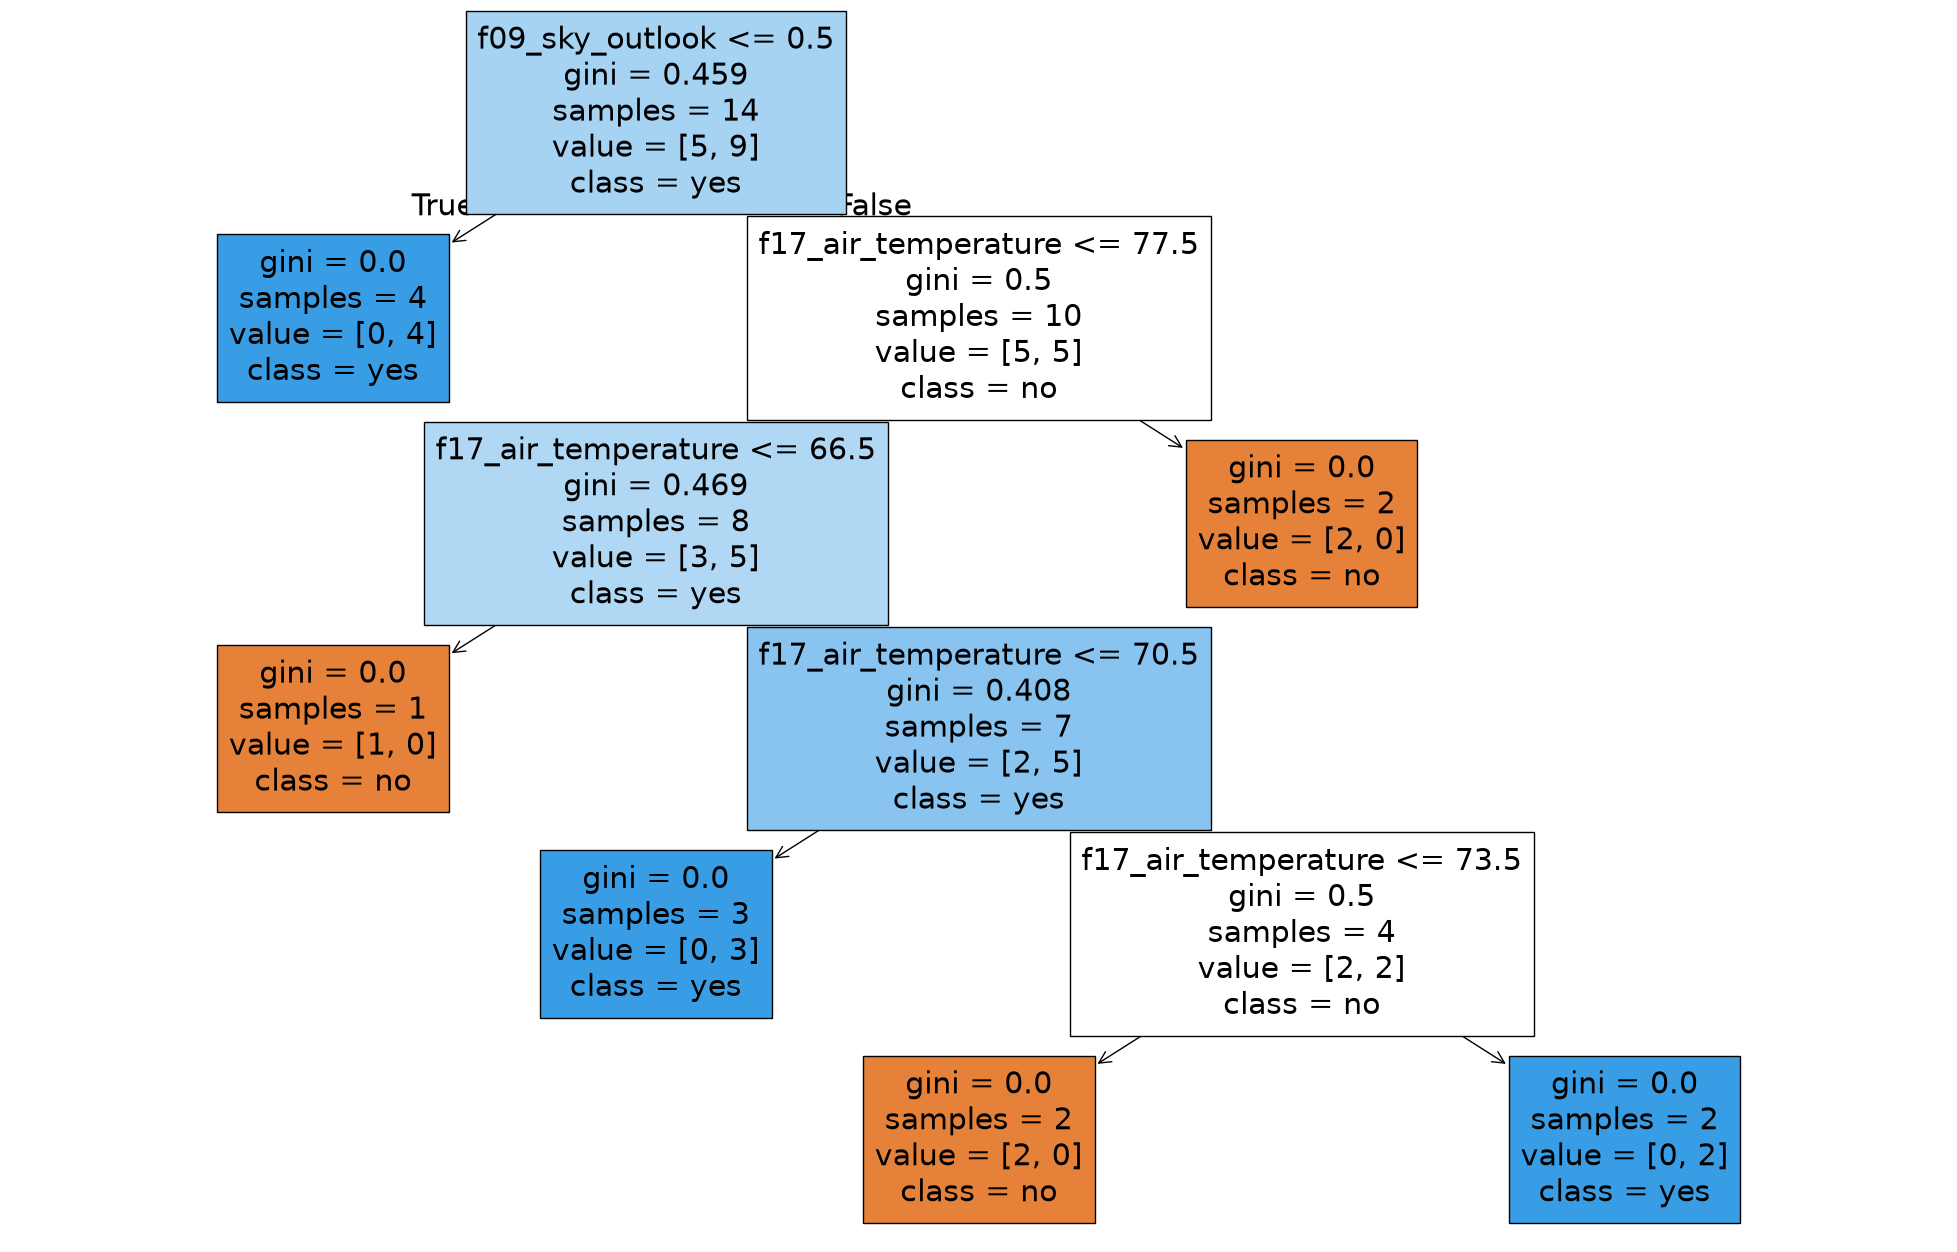

In [15]:
# Fit the configured model with its existing parameters.
# Can  also output the tree.
dt_clf.fit(golf_X, golf_y)
plt.figure(figsize=(25, 16))
plot_tree(dt_clf, filled=True,
          feature_names=list(golf_X.columns),
          class_names=dt_clf.classes_)

In [16]:
# Inspect the current dataframe to confirm its structure and values.
# Make a copy of the original golf data.
golf2 = golf.copy()
# 2.1. aggregate temperature and humidity by taking the average between them.
golf2['Temperature_Humidity'] = (golf2.f17_air_temperature + golf2.f06_humidity_level)/2
golf2.head()

,f09_sky_outlook,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision,Temperature_Humidity
0,sunny,85,85,False,no,85.0
1,sunny,80,90,True,no,85.0
2,overcast,83,78,False,yes,80.5
3,rain,70,96,False,yes,83.0
4,rain,68,80,False,yes,74.0


In [17]:
# Inspect the current dataframe to confirm its structure and values.
# 2.2. aggregate outlook and wind by concatenating their values.
# First, convert them to str, otherwise the concatenation will fail.
golf2[['f09_sky_outlook', 'f22_wind_condition']] = golf2[['f09_sky_outlook', 'f22_wind_condition']].astype('str')
# Add the new aggregated attribute.
golf2['Outlook_Wind'] = golf2.f09_sky_outlook + '_' + golf2.f22_wind_condition
golf2.head()

,f09_sky_outlook,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision,Temperature_Humidity,Outlook_Wind
0,sunny,85,85,False,no,85.0,sunny_False
1,sunny,80,90,True,no,85.0,sunny_True
2,overcast,83,78,False,yes,80.5,overcast_False
3,rain,70,96,False,yes,83.0,rain_False
4,rain,68,80,False,yes,74.0,rain_False


In [18]:
# Continue the analysis using the original transformation and model parameters.
# 2.3. combine the values of rain and overcast in the outlook column.
golf2['f09_sky_outlook'].mask((golf2.f09_sky_outlook == 'rain')|(golf2.f09_sky_outlook == 'overcast'),
                      'rain_overcast', inplace=True)
golf2

,f09_sky_outlook,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision,Temperature_Humidity,Outlook_Wind
0,sunny,85,85,False,no,85.0,sunny_False
1,sunny,80,90,True,no,85.0,sunny_True
2,overcast,83,78,False,yes,80.5,overcast_False
3,rain,70,96,False,yes,83.0,rain_False
4,rain,68,80,False,yes,74.0,rain_False
5,rain,65,70,True,no,67.5,rain_True
6,overcast,64,65,True,yes,64.5,overcast_True
7,sunny,72,95,False,no,83.5,sunny_False
8,sunny,69,70,False,yes,69.5,sunny_False
9,rain,75,80,False,yes,77.5,rain_False


In [19]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Remove the specified fields or rows for this experimental variant.
golf2 = golf2.drop(['f17_air_temperature', 'f06_humidity_level', 'f22_wind_condition'], axis=1)
# Separate the reg.attr. from the label attr.
golf_X2 = golf2[golf2.columns.difference(['f10_play_decision'])]
golf_y2 = golf2['f10_play_decision']
# Convert obj. cols to category cols.
enc = OrdinalEncoder()
golf_X2[['f09_sky_outlook', 'Outlook_Wind']] = enc.fit_transform(golf_X2[['f09_sky_outlook', 'Outlook_Wind']])
# We will use a DT to model a baseline.
dt_clf = DecisionTreeClassifier(random_state=43)
# Only do crossval since we have a very small dataset.
ad.report_classification_cv(golf_X2, golf_y2, dt_clf)

Mean Accuracy is 60.00 +/- 38.87
Mean Precision is 51.67 +/- 40.96
Mean Recall is 55.00 +/- 40.00
Mean F-score is 53.00 +/- 40.45


[Text(0.4, 0.875, 'Outlook_Wind <= 2.5\ngini = 0.459\nsamples = 14\nvalue = [5, 9]\nclass = yes'),
 Text(0.2, 0.625, 'gini = 0.0\nsamples = 7\nvalue = [0, 7]\nclass = yes'),
 Text(0.30000000000000004, 0.75, 'True  '),
 Text(0.6, 0.625, 'Temperature_Humidity <= 74.0\ngini = 0.408\nsamples = 7\nvalue = [5, 2]\nclass = no'),
 Text(0.5, 0.75, '  False'),
 Text(0.4, 0.375, 'Temperature_Humidity <= 68.5\ngini = 0.444\nsamples = 3\nvalue = [1, 2]\nclass = yes'),
 Text(0.2, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]\nclass = no'),
 Text(0.6, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]\nclass = yes'),
 Text(0.8, 0.375, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]\nclass = no')]

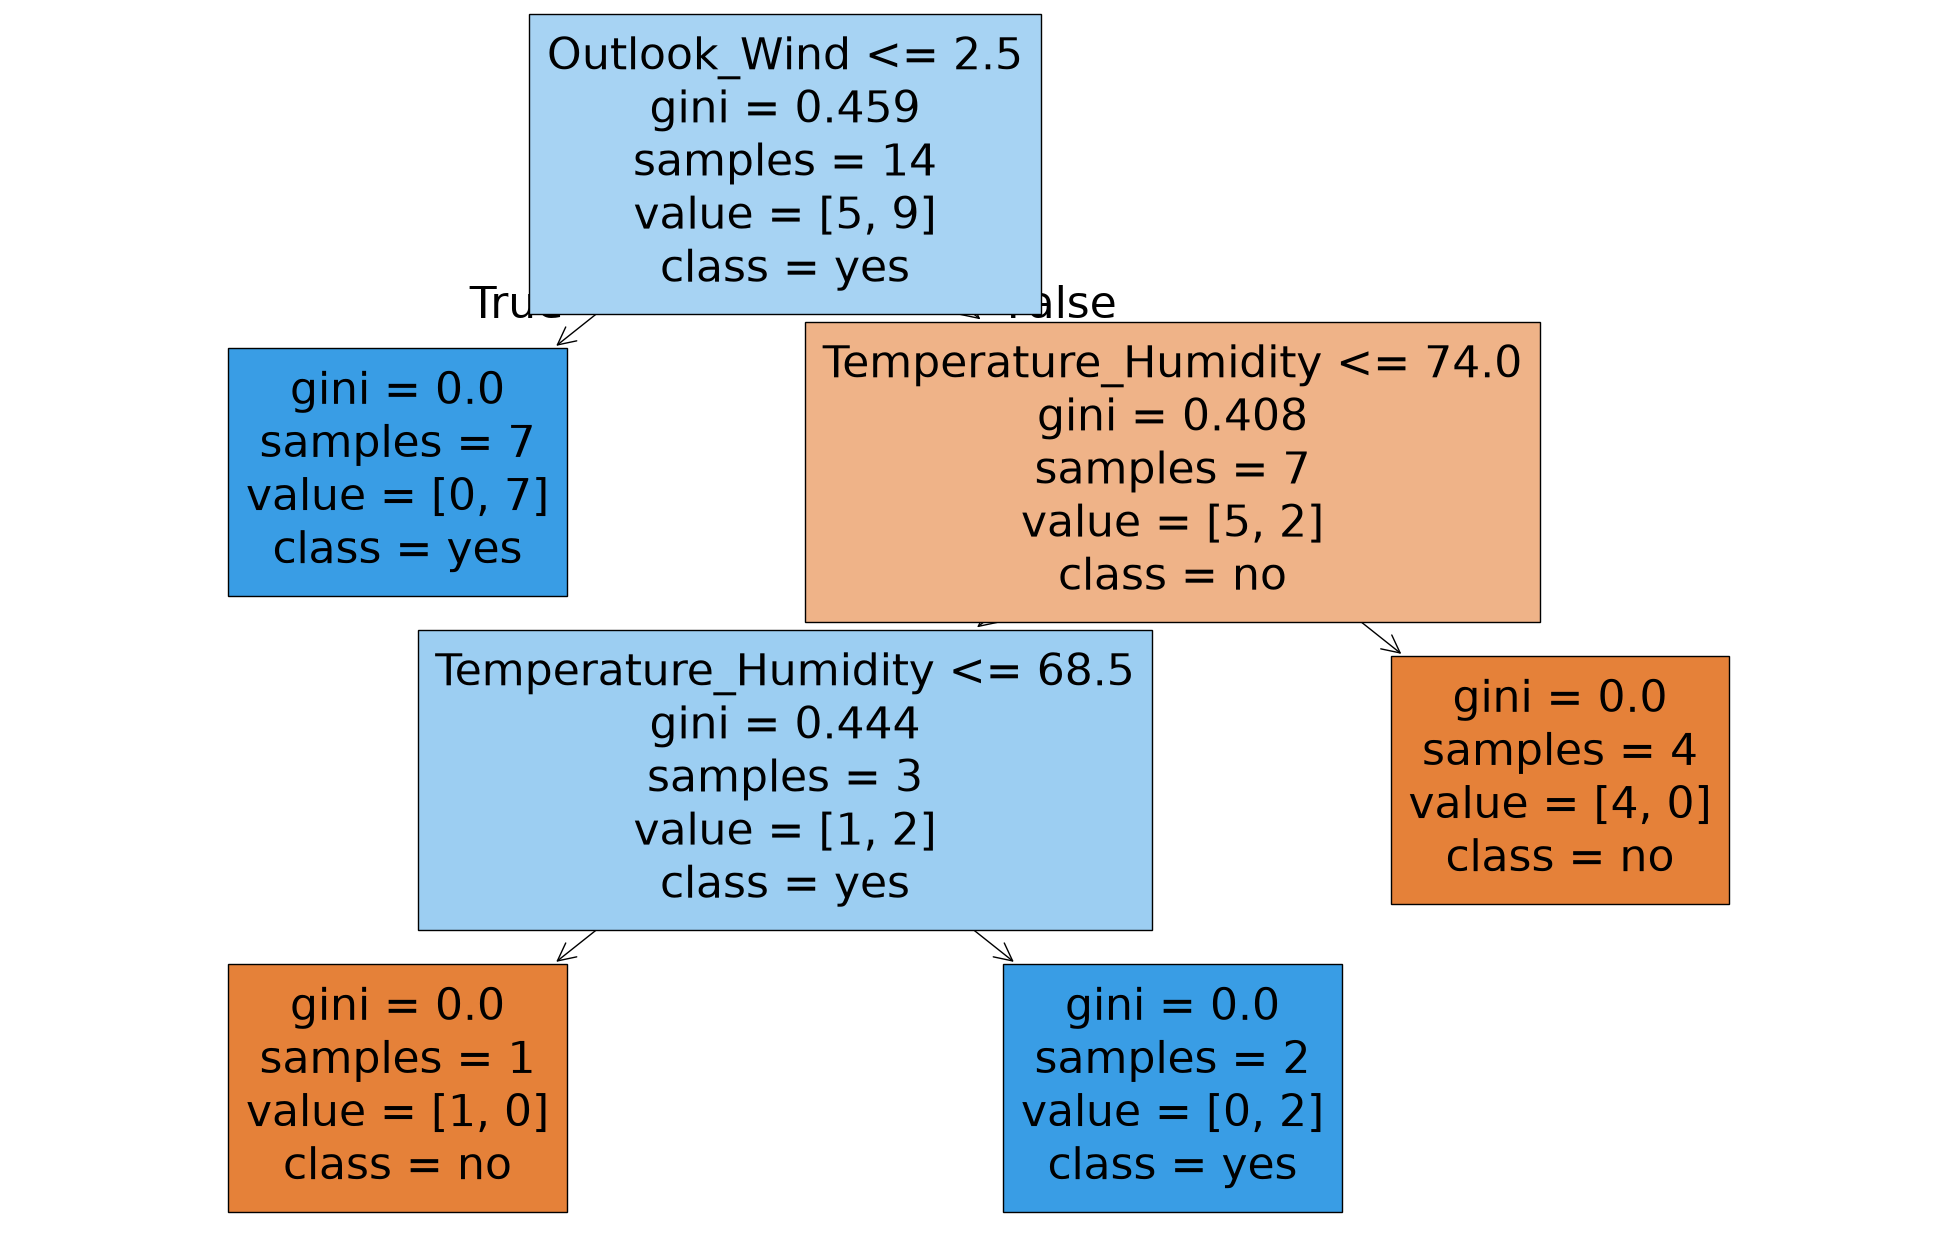

In [20]:
# Fit the configured model with its existing parameters.
# Can  also output the tree.
dt_clf.fit(golf_X2, golf_y2)
plt.figure(figsize=(25, 16))
plot_tree(dt_clf, filled=True,
          feature_names=list(golf_X2.columns),
          class_names=dt_clf.classes_)

## 2. Sampling methods

Explore alternative sampling strategies using botanical observations. Keep track of the sampling scheme and selected records when comparing downstream results.

In [21]:
# Load the project dataset from its local data directory and inspect its schema.
iris = pd.read_csv('data/flower_observations.csv', sep=';')
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   f33_sepal_length_cm  150 non-null    float64
 1   f34_sepal_width_cm   150 non-null    float64
 2   f31_petal_length_cm  150 non-null    float64
 3   f32_petal_width_cm   150 non-null    float64
 4   f29_flower_category  150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [22]:
# Inspect or update the intermediate result produced by the preceding step.
# 1.1. sample randomly half the rows using the fraction argument.
iris_rand_sample = iris.sample(frac=0.5, random_state=43, axis=0)
iris_rand_sample.f29_flower_category.value_counts()

f29_flower_category
Iris-versicolor    30
Iris-setosa        24
Iris-virginica     21
Name: count, dtype: int64

In [26]:
# Inspect or update the intermediate result produced by the preceding step.
# 1.2. sample randomly half the rows using the exact number of rows.
iris_rand_sample2 = iris.sample(n=75, random_state=43, axis=0)
iris_rand_sample2.f29_flower_category.value_counts()

f29_flower_category
Iris-versicolor    30
Iris-setosa        24
Iris-virginica     21
Name: count, dtype: int64

In [27]:

# Generate a stratified sample by selecting 50% of the
# observations independently from each flower category.
# Retain the original attributes, including the category label.
iris_rand_sample3 = pd.concat([
    group.sample(frac=0.5, random_state=43)
    for _, group in iris.groupby('f29_flower_category')
])

# Verify the number of observations retained per category.
iris_rand_sample3['f29_flower_category'].value_counts()


f29_flower_category
Iris-setosa        25
Iris-versicolor    25
Iris-virginica     25
Name: count, dtype: int64

In [28]:
# Environment setup: install the packages used by this notebook in the selected kernel.
# 3. sampling appox. 2/3 of rows with kernard stone.
# Need to install the necessary library if not already on the system.
!pip install kennard_stone
import kennard_stone
ks_X = iris.drop(['f29_flower_category'], axis=1)
ks_y = iris['f29_flower_category']
# Can use the train_test_split which works the same as the scikit version.
# So we can split based on the label column.
ks_X_sample, _, ks_y_sample, _ = kennard_stone.train_test_split(
    ks_X, ks_y, test_size=0.3, random_state=43
    )
print(len(ks_X_sample), len(ks_y_sample))
# Optionally we can put back together all attributes.
ks_sample = pd.concat([ks_X_sample, ks_y_sample], axis=1)
ks_sample.f29_flower_category.value_counts()

2026-11-04 18:38:59,600 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.

2026-11-04 18:38:59,603 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



105 105


f29_flower_category
Iris-virginica     41
Iris-versicolor    37
Iris-setosa        27
Name: count, dtype: int64

In [29]:
# Create the predefined training and validation partitions without changing split parameters.
# Or we can split independent of the class label column in which case.
# We need to convert the label attr because only works for numeric attributes.
ks_iris = iris.copy()
enc = LabelEncoder()
ks_iris['f29_flower_category'] = ks_iris[['f29_flower_category']].apply(enc.fit_transform)
# Keep 2/3.
ks_iris_sample, _ = kennard_stone.train_test_split(ks_iris, test_size=0.3, random_state=43)
# Reverse the encoding.
ks_iris_sample.f29_flower_category = ks_iris_sample[['f29_flower_category']].apply(enc.inverse_transform)
ks_iris_sample.f29_flower_category.value_counts()

2026-11-04 18:39:03,167 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.

2026-11-04 18:39:03,169 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



f29_flower_category
Iris-virginica     40
Iris-versicolor    37
Iris-setosa        28
Name: count, dtype: int64

In [30]:
# Inspect the current dataframe to confirm its structure and values.
charity.info()

<class 'pandas.DataFrame'>
RangeIndex: 2398 entries, 0 to 2397
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   f12_spend_before_campaign   2398 non-null   float64
 1   f14_visits_before_campaign  2398 non-null   float64
 2   f13_previous_spend_band     2398 non-null   str    
 3   f15_previous_visits_band    2398 non-null   str    
 4   f19_overall_visit_count     2398 non-null   float64
 5   f20_overall_spend_amount    2398 non-null   float64
 6   f11_postal_area             2398 non-null   str    
 7   f01_mosaic_segment          2398 non-null   float64
 8   f08_mosaic_band             2398 non-null   float64
 9   f18_salutation              2398 non-null   str    
 10  f04_gender_code             2398 non-null   str    
 11  f23_birth_year              2398 non-null   float64
 12  f02_age_years               2398 non-null   float64
 13  f03_age_band                2398 non-null   

<Axes: >

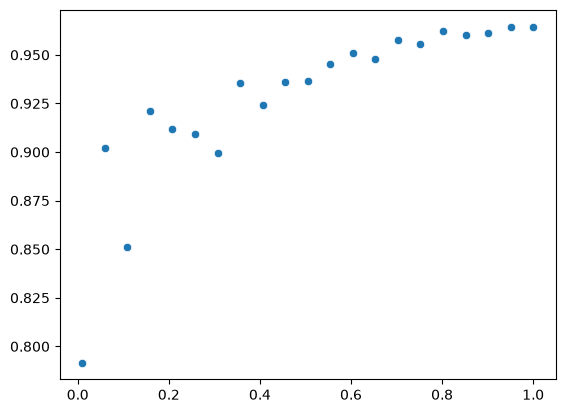

In [32]:

import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score

# Initialize the classifier and collect performance measurements.
accuracies = []
dt_clf = DecisionTreeClassifier(random_state=43)

# Define 21 progressively increasing sampling fractions.
sizes = np.linspace(0.01, 1, num=21, endpoint=True)

# Evaluate classification accuracy at each sampling fraction.
for size in sizes:

    # Sample the same proportion from each response category,
    # retaining the original class labels and feature values.
    sample = pd.concat([
        group.sample(frac=size, random_state=43)
        for _, group in charity.groupby('f16_campaign_response')
    ])

    # Separate predictor attributes from the response variable.
    X = sample[
        sample.columns.difference(['f16_campaign_response'])
    ].copy()

    y = sample['f16_campaign_response']

    # Identify categorical predictors requiring numerical encoding.
    obj_cols = X.select_dtypes(include=['object']).columns

    # Encode categorical attributes without changing the model configuration.
    ord_enc = OrdinalEncoder()
    X[obj_cols] = ord_enc.fit_transform(X[obj_cols])

    # Generate cross-validated predictions using the original classifier.
    preds = cross_val_predict(dt_clf, X, y)

    # Record the accuracy obtained for the current sample size.
    accuracies.append(accuracy_score(y, preds))

# Visualize how classification accuracy evolves with sample size.
sns.scatterplot(x=sizes, y=accuracies)


In [ ]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.

## 3. Class-balance methods

Use body-measurement categories to contrast the original distribution with undersampling, oversampling and SMOTE. Resampling should be restricted to the training portion when measuring generalization.

In [33]:
# Load the project dataset from its local data directory and inspect its schema.
bmi = pd.read_csv('data/body_measurement_classes.csv')
bmi.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   f04_gender_code      500 non-null    str  
 1   f05_height_cm        500 non-null    int64
 2   f21_weight_kg        500 non-null    int64
 3   f07_body_mass_group  500 non-null    str  
dtypes: int64(2), str(2)
memory usage: 15.8 KB


In [34]:
# Inspect or update the intermediate result produced by the preceding step.
bmi['f07_body_mass_group'].value_counts()

f07_body_mass_group
overweight     396
normal          69
underweight     35
Name: count, dtype: int64

In [35]:
# Create the predefined training and validation partitions without changing split parameters.
# Separate the reg.attr. from the label attr.
bmi_X = bmi[bmi.columns.difference(['f07_body_mass_group'])]
bmi_y = bmi['f07_body_mass_group']
# Convert obj. cols to category cols.
bmi_obj_cols = bmi_X.select_dtypes(include=['object']).columns
ord_enc = OrdinalEncoder()
bmi_X[bmi_obj_cols] = ord_enc.fit_transform(bmi_X[bmi_obj_cols])
X_train, X_test, y_train, y_test = train_test_split(bmi_X, bmi_y, test_size=0.3, random_state=43)
y_train.value_counts()

f07_body_mass_group
overweight     276
normal          50
underweight     24
Name: count, dtype: int64

In [36]:
# Evaluate the current estimator using the configured cross-validation strategy.
dt_clf = DecisionTreeClassifier(random_state=43)
# 0. get baseline model.
ad.report_classification_cv(X_train, y_train, dt_clf)
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))

Mean Accuracy is 92.00 +/- 3.21
Mean Precision is 85.35 +/- 6.44
Mean Recall is 81.24 +/- 7.73
Mean F-score is 81.75 +/- 7.36
              precision    recall  f1-score   support

      normal       0.79      0.58      0.67        19
  overweight       0.97      0.98      0.98       120
 underweight       0.71      0.91      0.80        11

    accuracy                           0.93       150
   macro avg       0.82      0.82      0.81       150
weighted avg       0.93      0.93      0.92       150



In [37]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 1. undersampling.
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(sampling_strategy='auto', random_state=43)
X_under, y_under = rus.fit_resample(X_train, y_train)
print(len(X_under), len(y_under))
print(y_under.value_counts())

72 72
f07_body_mass_group
normal         24
overweight     24
underweight    24
Name: count, dtype: int64


In [38]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Validate within each fold to ensure you account for instance leakage.
prep = RandomUnderSampler(random_state=43)
ad.evaluate_pipeline_cv(dt_clf, prep, X_train, y_train, imblearn_=True)
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))

Mean Accuracy is 86.86 +/- 1.90
Mean Precision is 74.09 +/- 6.53
Mean Recall is 84.80 +/- 8.60
Mean F-score is 77.95 +/- 7.30
              precision    recall  f1-score   support

      normal       0.55      0.63      0.59        19
  overweight       0.98      0.92      0.95       120
 underweight       0.69      1.00      0.81        11

    accuracy                           0.89       150
   macro avg       0.74      0.85      0.78       150
weighted avg       0.91      0.89      0.89       150



In [39]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 2. oversampling.
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=34)
X_over, y_over = ros.fit_resample(X_train, y_train)
print(len(X_over), len(y_over))
print(y_over.value_counts())

828 828
f07_body_mass_group
overweight     276
underweight    276
normal         276
Name: count, dtype: int64


In [40]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Validate within each fold to ensure you account for instance leakage.
prep = RandomOverSampler(random_state=43)
ad.evaluate_pipeline_cv(dt_clf, prep, X_train, y_train, imblearn_=True)
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))

Mean Accuracy is 94.00 +/- 2.10
Mean Precision is 88.78 +/- 4.56
Mean Recall is 87.27 +/- 9.05
Mean F-score is 87.11 +/- 6.50
              precision    recall  f1-score   support

      normal       0.73      0.58      0.65        19
  overweight       0.97      0.97      0.97       120
 underweight       0.69      1.00      0.81        11

    accuracy                           0.92       150
   macro avg       0.80      0.85      0.81       150
weighted avg       0.92      0.92      0.92       150



In [41]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 3. SMOTE.
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=43, k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print(len(X_smote), len(y_smote))
print(y_smote.value_counts())

828 828
f07_body_mass_group
overweight     276
underweight    276
normal         276
Name: count, dtype: int64


In [42]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Validate within each fold to ensure you account for instance leakage.
prep = SMOTE(random_state=43)
ad.evaluate_pipeline_cv(dt_clf, prep, X_train, y_train, imblearn_=True)
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))
# Optional comparison: review this configuration against the original baseline.

Mean Accuracy is 94.86 +/- 1.46
Mean Precision is 87.13 +/- 5.10
Mean Recall is 86.97 +/- 7.69
Mean F-score is 86.22 +/- 6.50
              precision    recall  f1-score   support

      normal       0.74      0.74      0.74        19
  overweight       0.98      0.97      0.97       120
 underweight       0.77      0.91      0.83        11

    accuracy                           0.93       150
   macro avg       0.83      0.87      0.85       150
weighted avg       0.94      0.93      0.93       150



In [43]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 3.b. Borderline SMOTE.
from imblearn.over_sampling import BorderlineSMOTE
blsmote = BorderlineSMOTE(random_state=43, k_neighbors=5, m_neighbors=10, kind='borderline-1')
X_blsmote, y_blsmote = blsmote.fit_resample(X_train, y_train)
print(len(X_blsmote), len(y_blsmote))
print(y_blsmote.value_counts())

828 828
f07_body_mass_group
overweight     276
underweight    276
normal         276
Name: count, dtype: int64


In [44]:
# Evaluate the current estimator using the configured cross-validation strategy.
# Validate within each fold to ensure you account for instance leakage.
prep = BorderlineSMOTE(random_state=43, k_neighbors=7, m_neighbors=16)
ad.evaluate_pipeline_cv(dt_clf, prep, X_train, y_train, imblearn_=True)
y_pred = dt_clf.predict(X_test)
print(classification_report(y_test, y_pred))
# Optional comparison: review this configuration against the original baseline.
# Optional comparison: review this configuration against the original baseline.
# And ADASYN hyperparameters, and attempt to experiment with different combinations.

Mean Accuracy is 96.00 +/- 1.40
Mean Precision is 92.16 +/- 2.62
Mean Recall is 91.73 +/- 4.23
Mean F-score is 90.80 +/- 3.48
              precision    recall  f1-score   support

      normal       0.79      0.79      0.79        19
  overweight       0.99      0.97      0.98       120
 underweight       0.79      1.00      0.88        11

    accuracy                           0.95       150
   macro avg       0.86      0.92      0.88       150
weighted avg       0.95      0.95      0.95       150



## 4. Encode categorical fields

Consider ordinal mappings and indicator variables. The numerical representation should reflect whether a category has a meaningful order.

In [46]:

# Create an independent copy of the original dataset.
golf3 = golf.copy()

# Define the numerical representation of each sky condition.
outlook_mapping = {
    'sunny': 1,
    'overcast': 2,
    'rain': 3
}

# Convert categorical weather conditions into integer codes.
golf3['f09_sky_outlook'] = (
    golf3['f09_sky_outlook']
    .map(outlook_mapping)
    .astype('int64')
)

# Inspect the transformed dataset.
golf3.head()


,f09_sky_outlook,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision
0,1,85,85,False,no
1,1,80,90,True,no
2,2,83,78,False,yes
3,3,70,96,False,yes
4,3,68,80,False,yes


In [47]:
# Inspect the current dataframe to confirm its structure and values.
# 2. dummy encoding/one-hot-encoding using pandas.
# Note: sklearn also has the OneHotEncoder class to do this.
# Make a copy first.
golf5 = golf.copy()
golf5 = pd.get_dummies(golf5, columns=['f09_sky_outlook'])
golf5.head()

,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision,f09_sky_outlook_overcast,f09_sky_outlook_rain,f09_sky_outlook_sunny
0,85,85,False,no,False,False,True
1,80,90,True,no,False,False,True
2,83,78,False,yes,True,False,False
3,70,96,False,yes,False,True,False
4,68,80,False,yes,False,True,False


In [48]:
# Inspect the current dataframe to confirm its structure and values.
# 3. numeric to binomial using a boolean mask or lambdas, e.g. True if <=85, False otherwise.
# Make a copy first.
golf6 = golf.copy()
golf6['f06_humidity_level']= golf6['f06_humidity_level'].apply(lambda x: True if x <= 85 else False)
golf6.head()

,f09_sky_outlook,f17_air_temperature,f06_humidity_level,f22_wind_condition,f10_play_decision
0,sunny,85,True,False,no
1,sunny,80,False,True,no
2,overcast,83,True,False,yes
3,rain,70,False,False,yes
4,rain,68,True,False,yes


In [49]:
# Inspect the current dataframe to confirm its structure and values.
# 4. numeric to polynomial, e.g., in temperature each value becomes a string.
# Make a copy first.
golf7 = golf.copy()
golf7.f17_air_temperature = golf7.f17_air_temperature.apply(lambda x: str(x))
golf7.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   f09_sky_outlook      14 non-null     str  
 1   f17_air_temperature  14 non-null     str  
 2   f06_humidity_level   14 non-null     int64
 3   f22_wind_condition   14 non-null     bool 
 4   f10_play_decision    14 non-null     str  
dtypes: bool(1), int64(1), str(3)
memory usage: 594.0 bytes


### Standardize and rescale numerical data

Compare min–max scaling, standard scaling and robust transformations. Scaling matters particularly for distance-sensitive models.

In [50]:
# Load the project dataset from its local data directory and inspect its schema.
iris = pd.read_csv('data/flower_observations.csv', sep=';')
# Separate regular attributes from the label column.
X_iris = iris[iris.columns.difference(['f29_flower_category'])]
y_iris = iris['f29_flower_category']

array([[<Axes: title={'center': 'f34_sepal_width_cm'}>,
        <Axes: title={'center': 'mm'}>],
       [<Axes: title={'center': 'std'}>, <Axes: title={'center': 'iqr'}>]],
      dtype=object)

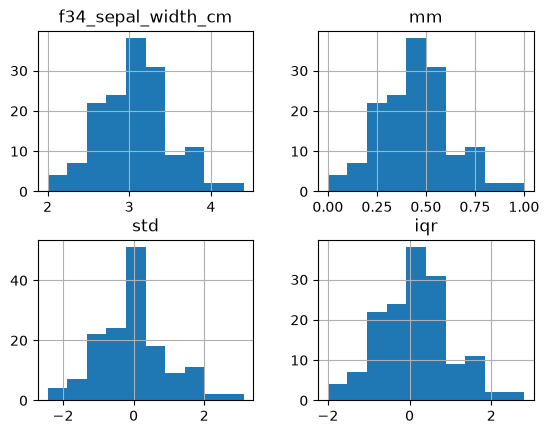

In [51]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
scaled = X_iris[['f34_sepal_width_cm']].copy()
scaled[['mm']] = MinMaxScaler().fit_transform(scaled[['f34_sepal_width_cm']])
scaled[['std']] = StandardScaler().fit_transform(scaled[['f34_sepal_width_cm']])
scaled[['iqr']] = RobustScaler().fit_transform(scaled[['f34_sepal_width_cm']])
scaled.hist()

In [52]:
# Inspect or update the intermediate result produced by the preceding step.
# Optional comparison: review this configuration against the original baseline.
# Generate a baseline through crossvalidation on the training portion then apply last model to the test portion.
# Then use a similar approach, but this time, choose an appropriate scaling method to include in the pipeline;
# Compare and discuss performances.

### Mathematical feature transformations

Apply mathematical transformations and retain the original measurements temporarily to inspect how the transformed distributions differ.

In [53]:
# Load the project dataset from its local data directory and inspect its schema.
poly = pd.read_csv('data/polynomial_input_features.csv', sep=';')
poly.head()

,f24_polynomial_basis_01,f25_polynomial_basis_02,f26_polynomial_basis_03,f27_polynomial_basis_04,f28_polynomial_basis_05,f30_polynomial_response
0,0.636574,8.442168,2.116100,2.771868,8.448427,88.016325
1,4.595454,4.388042,4.926094,2.682404,8.617752,138.754854
2,4.292060,0.861090,9.157984,6.607498,4.084605,38.283872
3,8.559949,3.856238,1.038135,1.687798,2.893063,82.147784
4,2.272321,1.834079,6.300621,1.937969,2.069888,33.790021


In [54]:
# Inspect the current dataframe to confirm its structure and values.
# 1. 1/x.
poly['one/f24_polynomial_basis_01'] = 1/poly.f24_polynomial_basis_01
poly.head()

,f24_polynomial_basis_01,f25_polynomial_basis_02,f26_polynomial_basis_03,f27_polynomial_basis_04,f28_polynomial_basis_05,f30_polynomial_response,one/f24_polynomial_basis_01
0,0.636574,8.442168,2.116100,2.771868,8.448427,88.016325,1.570909
1,4.595454,4.388042,4.926094,2.682404,8.617752,138.754854,0.217606
2,4.292060,0.861090,9.157984,6.607498,4.084605,38.283872,0.232988
3,8.559949,3.856238,1.038135,1.687798,2.893063,82.147784,0.116823
4,2.272321,1.834079,6.300621,1.937969,2.069888,33.790021,0.440079


In [55]:
# Inspect the current dataframe to confirm its structure and values.
# 2. exponential(x).
poly['exp(f24_polynomial_basis_01)'] = poly.f24_polynomial_basis_01.apply(np.exp)
poly.head()

,f24_polynomial_basis_01,f25_polynomial_basis_02,f26_polynomial_basis_03,f27_polynomial_basis_04,f28_polynomial_basis_05,f30_polynomial_response,one/f24_polynomial_basis_01,exp(f24_polynomial_basis_01)
0,0.636574,8.442168,2.116100,2.771868,8.448427,88.016325,1.570909,1.889995
1,4.595454,4.388042,4.926094,2.682404,8.617752,138.754854,0.217606,99.033102
2,4.292060,0.861090,9.157984,6.607498,4.084605,38.283872,0.232988,73.116940
3,8.559949,3.856238,1.038135,1.687798,2.893063,82.147784,0.116823,5218.417475
4,2.272321,1.834079,6.300621,1.937969,2.069888,33.790021,0.440079,9.701890


In [56]:
# Inspect the current dataframe to confirm its structure and values.
# 3. sqrt(x).
poly['sqrt(f24_polynomial_basis_01)'] = poly.f24_polynomial_basis_01.apply(np.sqrt)
poly.head()

,f24_polynomial_basis_01,f25_polynomial_basis_02,f26_polynomial_basis_03,f27_polynomial_basis_04,f28_polynomial_basis_05,f30_polynomial_response,one/f24_polynomial_basis_01,exp(f24_polynomial_basis_01),sqrt(f24_polynomial_basis_01)
0,0.636574,8.442168,2.116100,2.771868,8.448427,88.016325,1.570909,1.889995,0.797856
1,4.595454,4.388042,4.926094,2.682404,8.617752,138.754854,0.217606,99.033102,2.143701
2,4.292060,0.861090,9.157984,6.607498,4.084605,38.283872,0.232988,73.116940,2.071729
3,8.559949,3.856238,1.038135,1.687798,2.893063,82.147784,0.116823,5218.417475,2.925739
4,2.272321,1.834079,6.300621,1.937969,2.069888,33.790021,0.440079,9.701890,1.507422


In [57]:
# Inspect the current dataframe to confirm its structure and values.
# 4. log2(x).
poly['log2(f24_polynomial_basis_01)'] = poly.f24_polynomial_basis_01.apply(np.log2)
poly.head()

,f24_polynomial_basis_01,f25_polynomial_basis_02,f26_polynomial_basis_03,f27_polynomial_basis_04,f28_polynomial_basis_05,f30_polynomial_response,one/f24_polynomial_basis_01,exp(f24_polynomial_basis_01),sqrt(f24_polynomial_basis_01),log2(f24_polynomial_basis_01)
0,0.636574,8.442168,2.116100,2.771868,8.448427,88.016325,1.570909,1.889995,0.797856,-0.651600
1,4.595454,4.388042,4.926094,2.682404,8.617752,138.754854,0.217606,99.033102,2.143701,2.200207
2,4.292060,0.861090,9.157984,6.607498,4.084605,38.283872,0.232988,73.116940,2.071729,2.101670
3,8.559949,3.856238,1.038135,1.687798,2.893063,82.147784,0.116823,5218.417475,2.925739,3.097602
4,2.272321,1.834079,6.300621,1.937969,2.069888,33.790021,0.440079,9.701890,1.507422,1.184166


### Normalize text labels

Use consistent string casing and formatting to avoid treating different spellings of the same category as separate values.

In [58]:
# Inspect or update the intermediate result produced by the preceding step.
# Capitalising all values in 'Outlook'.
golf['f09_sky_outlook'].apply(lambda x: x.upper())

0        SUNNY
1        SUNNY
2     OVERCAST
3         RAIN
4         RAIN
5         RAIN
6     OVERCAST
7        SUNNY
8        SUNNY
9         RAIN
10       SUNNY
11    OVERCAST
12    OVERCAST
13        RAIN
Name: f09_sky_outlook, dtype: str

In [59]:
# Inspect or update the intermediate result produced by the preceding step.
# Getting the number of characters in each value.
golf['f09_sky_outlook'].apply(lambda x: len(x))

0     5
1     5
2     8
3     4
4     4
5     4
6     8
7     5
8     5
9     4
10    5
11    8
12    8
13    4
Name: f09_sky_outlook, dtype: int64

In [60]:
# Inspect or update the intermediate result produced by the preceding step.
golf['f09_sky_outlook'].apply(lambda x: x.startswith('s'))

0      True
1      True
2     False
3     False
4     False
5     False
6     False
7      True
8      True
9     False
10     True
11    False
12    False
13    False
Name: f09_sky_outlook, dtype: bool

## 5. Construct additional features

Create derived fields with pandas and Feature-engine while retaining the original inputs for comparison. New features are useful only if they add predictive information.

In [61]:
# Inspect the current dataframe to confirm its structure and values.
# 1. using pandas.
# Make a copy.
golf8 = golf_X.copy()
# Derive a temperature-to-humidity ratio for comparison without assuming a causal relationship.
golf8['temp/hum'] = golf_X.f17_air_temperature / golf_X.f06_humidity_level
golf8.head()

,f06_humidity_level,f09_sky_outlook,f17_air_temperature,f22_wind_condition,temp/hum
0,85,2,85,False,1.000000
1,90,2,80,True,0.888889
2,78,0,83,False,1.064103
3,96,1,70,False,0.729167
4,80,1,68,False,0.850000


In [62]:
# Load the numerical, visualization, and machine-learning utilities for this workflow.
# 2. use feature engine library to create new features through DT supervised leaning.
from feature_engine.creation import DecisionTreeFeatures
# Create a copy.
golf9= golf_X.copy()
# A. create all possible combinations of any 1 and 2 existing features.
dtf = DecisionTreeFeatures(features_to_combine=2, regression=False, random_state=43)
# Add the new features.
golf9 = dtf.fit_transform(golf9, golf_y)
golf9.head()

,f06_humidity_level,f09_sky_outlook,f17_air_temperature,f22_wind_condition,tree(f06_humidity_level),tree(f09_sky_outlook),tree(f17_air_temperature),"tree(['f06_humidity_level', 'f09_sky_outlook'])","tree(['f06_humidity_level', 'f17_air_temperature'])","tree(['f09_sky_outlook', 'f17_air_temperature'])"
0,85,2,85,False,0.400000,0.5,0.000000,0.5,0.400000,0.5
1,90,2,80,True,0.400000,0.5,0.692308,0.5,0.400000,0.5
2,78,0,83,False,0.777778,1.0,0.692308,1.0,0.777778,1.0
3,96,1,70,False,0.400000,0.5,0.692308,0.5,0.400000,0.5
4,80,1,68,False,0.777778,0.5,0.692308,0.5,0.777778,0.5


In [63]:
# Inspect the current dataframe to confirm its structure and values.
# Create a copy.
golf10= golf_X.copy()
# A. create all possible combinations of any 2 existing features.
dtf = DecisionTreeFeatures(features_to_combine=[2], regression=False, random_state=43)
# Add the new features.
golf10 = dtf.fit_transform(golf10, golf_y)
golf10.head()

,f06_humidity_level,f09_sky_outlook,f17_air_temperature,f22_wind_condition,"tree(['f06_humidity_level', 'f09_sky_outlook'])","tree(['f06_humidity_level', 'f17_air_temperature'])","tree(['f09_sky_outlook', 'f17_air_temperature'])"
0,85,2,85,False,0.5,0.400000,0.5
1,90,2,80,True,0.5,0.400000,0.5
2,78,0,83,False,1.0,0.777778,1.0
3,96,1,70,False,0.5,0.400000,0.5
4,80,1,68,False,0.5,0.777778,0.5


In [64]:
# Inspect the current dataframe to confirm its structure and values.
# Create a copy.
golf11= golf_X.copy()
# Create custom combinations of features.
features = (('f09_sky_outlook', 'f06_humidity_level'),
            ('f09_sky_outlook', 'f06_humidity_level', 'f17_air_temperature'))
dtf = DecisionTreeFeatures(features_to_combine=features, regression=False, random_state=43)
# Add the new features.
golf11 = dtf.fit_transform(golf11, golf_y)
golf11.head()

,f06_humidity_level,f09_sky_outlook,f17_air_temperature,f22_wind_condition,"tree(['f09_sky_outlook', 'f06_humidity_level'])","tree(['f09_sky_outlook', 'f06_humidity_level', 'f17_air_temperature'])"
0,85,2,85,False,0.5,0.5
1,90,2,80,True,0.5,0.5
2,78,0,83,False,1.0,1.0
3,96,1,70,False,0.5,0.5
4,80,1,68,False,0.5,0.5


### Further experiments

Compare selected configurations against the same baseline and validation protocol; note any effect of added features rather than assuming that more variables always help.